# 07 · Evaluation and error analysis

How the system is judged, how to read the numbers, and where it fails. Everything here is computed from the saved experiment results in
`eval/results/` (no model calls, no spend). The full write-up is `docs/EVAL_REPORT.md`.

1. The evaluation set
2. The metrics, run on small examples
3. Uncertainty: why 15 cases give wide intervals
4. Results by case type
5. Error taxonomy of the held-out failures
6. How far to trust the judge
7. The held-out runs side by side

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from policy_agent.eval import evaluators as ev
from policy_agent.eval.checks import load
from policy_agent.eval.models import EvalCase
from policy_agent.ingest.paths import ROOT

sys.path.insert(0, str(ROOT / "scripts"))
import analyse_final as af  # noqa: E402
import analyse_generation as ag  # noqa: E402
import calibrate_judge as cj  # noqa: E402

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)
cases = {c.id: c for c in load("eval_cases.jsonl", EvalCase)}
R = ROOT / "eval" / "results"
print(len(cases), "cases loaded")

36 cases loaded


## 1. The evaluation set
36 cases were written before any system existed, across the situations the task names. They are split once (seed 20261027, stratified by type) into `dev` (used while building) and `test` (held out).

In [2]:
df = pd.DataFrame(
    [
        {
            "id": c.id,
            "type": c.case_type,
            "split": c.split,
            "expected": c.expected_status,
            "tools": ",".join(c.requires_tools),
            "gold_chunks": len(c.gold_chunk_ids),
        }
        for c in cases.values()
    ]
)
display(pd.crosstab(df.type, df.split, margins=True))
display(pd.crosstab(df.type, df.expected))
for cid in ("F02", "K03", "C04"):
    c = cases[cid]
    print(
        f"\n{cid} [{c.case_type}, {c.split}] {c.question}\n  expected: {c.expected_status} | gold: {c.gold_answer[:200]}"
    )
    if c.conflict_values:
        print(
            "  conflict values:", [(v.label, v.value, "latest" if v.latest else "earlier") for v in c.conflict_values]
        )

split,dev,test,All
type,,,
adversarial,2,2,4
ambiguous,2,1,3
calculation,3,2,5
conflicting,2,2,4
factual,5,3,8
multi_step,4,3,7
unanswerable,3,2,5
All,21,15,36


expected,abstained,answered,conflict_reported,needs_clarification,refused
type,,,,,
adversarial,1,2,0,0,1
ambiguous,0,0,0,3,0
calculation,0,4,1,0,0
conflicting,0,0,4,0,0
factual,0,7,1,0,0
multi_step,0,7,0,0,0
unanswerable,5,0,0,0,0



F02 [factual, dev] What was the overall unemployment rate, seasonally adjusted, in the fourth quarter of 2023?
  expected: answered | gold: 2% (overall, seasonally adjusted, 4Q 2023).

K03 [calculation, dev] What was the percentage change in job vacancies between 2Q 2022 and 2Q 2026?
  expected: answered | gold: -45.0%, a fall of 45.0% (127,000 to 69,900).

C04 [conflicting, dev] What was the citizen unemployment rate in September 2025?
  expected: conflict_reported | gold: 3.1% per the Labour Market Report and the quarterly dataset; the preliminary Advance Release said 3.0%. Report both, say the earlier figure was preliminary, prefer the latest.
  conflict values: [('advance release 2025-10-30', 3.0, 'earlier'), ('labour market report 2025-12-11', 3.1, 'latest')]


## 2. The metrics, on small examples
Each metric is a small function you can run by hand. Numbers are compared **by value** (so `-45.0%`, `a fall of 45%` and `45` can all match within the case's tolerance; the unit label is not checked by this metric). Retrieval is scored against graded gold chunks.

In [3]:
k03 = cases["K03"]
ref = k03.model_dump()
for text in (
    "Job vacancies fell by 44.96063%, from 127,000 to 69,900.",
    "Job vacancies fell by 30%.",
    "Job vacancies fell by 4.5%.",
):
    out = {"text": text, "status": "answered", "answer": {}, "citations": []}
    print(
        f"{ev.numeric_exact(out, ref)['score']:.0f}  numeric_exact(gold {k03.gold_value}, tolerance {k03.tolerance}): {text}"
    )

gold = {k for k, g in cases["F03"].gold_chunk_ids.items() if g == 2}
ranked = ["x1", "x2", next(iter(gold)), "x3", "x4"]  # the answer-bearing chunk is third
ret = {"retrieved": ranked}
rel = cases["F03"].model_dump()
print({m.__name__: round(m(ret, rel)["score"], 3) for m in (ev.recall_at_5, ev.hit_at_5, ev.mrr_at_10, ev.ndcg_at_10)})
print(
    "MRR@10 = 1/3 because the answer-bearing chunk is at rank 3; Recall@5 is 1.0 because the only answer-bearing chunk is in the top 5."
)

1  numeric_exact(gold -45.0, tolerance 0.1): Job vacancies fell by 44.96063%, from 127,000 to 69,900.
0  numeric_exact(gold -45.0, tolerance 0.1): Job vacancies fell by 30%.
0  numeric_exact(gold -45.0, tolerance 0.1): Job vacancies fell by 4.5%.
{'recall_at_5': 1.0, 'hit_at_5': 1.0, 'mrr_at_10': 0.333, 'ndcg_at_10': 0.5}
MRR@10 = 1/3 because the answer-bearing chunk is at rank 3; Recall@5 is 1.0 because the only answer-bearing chunk is in the top 5.


## 3. Uncertainty: why a few cases give wide intervals
With 15 held-out cases, one case is 6.7 percentage points. A **bootstrap** resamples the cases with replacement many times and reads the spread of the resulting means. Differences between systems use the *same* resamples ("paired"), which is why a paired interval can be narrower than the two individual ones.

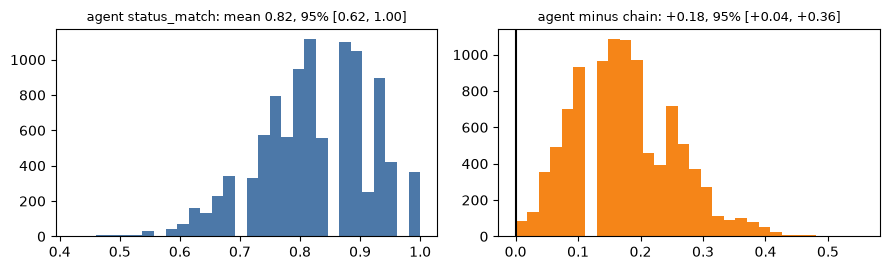

discordant cases: agent better on 3, chain better on 0; exact McNemar p = 0.25; Wilcoxon p = 0.12
The bootstrap interval excludes zero but the exact paired tests do not: with this few cases the evidence is suggestive, not conclusive.


In [4]:
agent, chain = af.read("E8T", "test"), af.read("E6T", "test")
a, c = ag.per_case(agent, "status_match"), ag.per_case(chain, "status_match")
cases_ids = sorted(set(a) & set(c))
x, y = np.array([a[i] for i in cases_ids]), np.array([c[i] for i in cases_ids])
rng = np.random.default_rng(20261027)
idx = rng.integers(0, len(cases_ids), size=(10_000, len(cases_ids)))
boot_a, boot_diff = x[idx].mean(1), (x - y)[idx].mean(1)
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].hist(boot_a, bins=30, color="#4C78A8")
ax[0].set_title(
    f"agent status_match: mean {x.mean():.2f}, 95% [{np.percentile(boot_a, 2.5):.2f}, {np.percentile(boot_a, 97.5):.2f}]",
    fontsize=9,
)
ax[1].hist(boot_diff, bins=30, color="#F58518")
ax[1].axvline(0, color="black")
ax[1].set_title(
    f"agent minus chain: {np.mean(boot_diff):+.2f}, 95% [{np.percentile(boot_diff, 2.5):+.2f}, {np.percentile(boot_diff, 97.5):+.2f}]",
    fontsize=9,
)
plt.tight_layout()
plt.show()
n_a_only, n_c_only, p = af.mcnemar_exact(a, c)
print(
    f"discordant cases: agent better on {n_a_only}, chain better on {n_c_only}; exact McNemar p = {p:.2f}; Wilcoxon p = {af.signed_rank_exact(x - y):.2f}"
)
print(
    "The bootstrap interval excludes zero but the exact paired tests do not: with this few cases the evidence is suggestive, not conclusive."
)

## 4. Results by case type
A single average hides where a system is weak. The same three systems on the dev split, by case type (`status_match`, mean over runs).

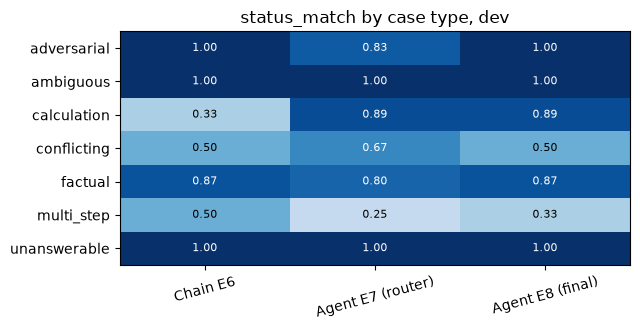

In [5]:
systems = {"Chain E6": "E6", "Agent E7 (router)": "E7", "Agent E8 (final)": "E8"}
table = pd.DataFrame(
    {
        name: {
            t: v.get("status_match", {}).get("mean")
            for t, v in json.loads((R / f"{cid}_dev.json").read_text())["by_case_type"].items()
        }
        for name, cid in systems.items()
    }
)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
im = ax.imshow(table.values.astype(float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(table.shape[1]))
ax.set_xticklabels(table.columns, rotation=15)
ax.set_yticks(range(table.shape[0]))
ax.set_yticklabels(table.index)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "black", fontsize=8)
ax.set_title("status_match by case type, dev")
plt.tight_layout()
plt.show()

## 5. Error taxonomy of the held-out failures
Each failed run gets one cause (first match wins): validation downgrade, tool failure, retrieval miss (no gold chunk reached the model), over-reported conflict, abstained when an answer was expected, and so on.

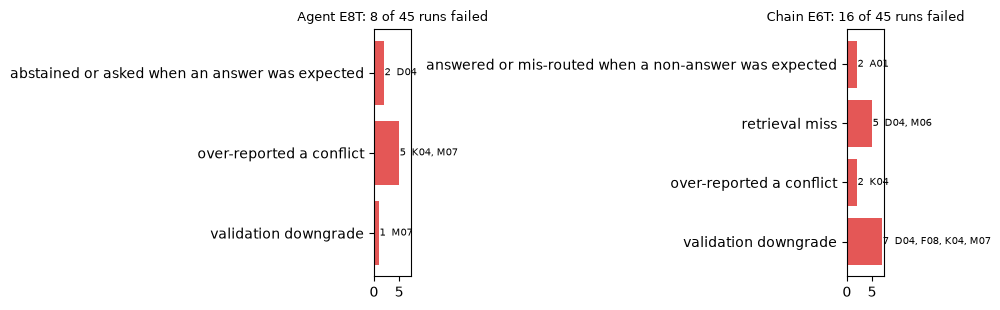

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for axis, (name, res) in zip(ax, (("Agent E8T", agent), ("Chain E6T", chain)), strict=True):
    kinds, where = af.taxonomy(res, cases)
    labels = [k.split(" (")[0] for k in kinds]
    axis.barh(labels, list(kinds.values()), color="#E45756")
    axis.invert_yaxis()
    axis.set_title(f"{name}: {sum(kinds.values())} of {res['n_runs']} runs failed", fontsize=9)
    for lab, v in zip(labels, kinds.values(), strict=True):
        axis.text(
            v + 0.1,
            lab,
            f"{v}  {', '.join(where[[k for k in kinds if k.startswith(lab)][0]])}",
            va="center",
            fontsize=7,
        )
plt.tight_layout()
plt.show()

## 6. How far to trust the judge
Groundedness is scored by an LLM from a different model family. It was checked against the project owner's blind labels on 29 claims (four were deliberately altered copies mixed in unmarked).

In [7]:
items = json.loads((ROOT / "eval" / "calibration" / "items.json").read_text())["items"]
labels, relevance = cj.read_labels((ROOT / "eval" / "CALIBRATION.md").read_text())
pairs = [
    (int(j), next(iter(labels[(it["item"], k)])))
    for it in items
    for k, j in enumerate(it["judge_claims"], 1)
    if len(labels.get((it["item"], k), set())) == 1
]
conf = pd.crosstab(
    pd.Series([p[1] for p in pairs], name="human: supported"), pd.Series([p[0] for p in pairs], name="judge: supported")
)
display(conf)
jj, hh = [p[0] for p in pairs], [p[1] for p in pairs]
print(
    f"claims labelled: {len(pairs)} | agreement {np.mean([a == b for a, b in pairs]):.2f} | Cohen's kappa {cj.cohen_kappa(jj, hh)}"
)
rel_pairs = [
    (int(it["judge_relevance"]), next(iter(relevance[it["item"]])))
    for it in items
    if len(relevance.get(it["item"], set())) == 1
]
print(
    f"relevance (1-5): exact agreement {np.mean([a == b for a, b in rel_pairs]):.2f}, within one point {np.mean([abs(a - b) <= 1 for a, b in rel_pairs]):.2f}"
)
print(
    "Reading: groundedness agrees on all claims (only 29, one labeller); the relevance judge is too lenient, so it is not used to rank systems."
)

judge: supported,0,1
human: supported,,
0,4,0
1,0,25


claims labelled: 29 | agreement 1.00 | Cohen's kappa 1.0
relevance (1-5): exact agreement 0.50, within one point 0.60
Reading: groundedness agrees on all claims (only 29, one labeller); the relevance judge is too lenient, so it is not used to rank systems.


## 7. The held-out runs side by side
The held-out split was used three times: the first agent design, then the final design twice with identical code. The spread between the two identical runs is the run-to-run noise.

In [8]:
runs = {
    "E7T router agent": af.read("E7T", "test"),
    "E8T first execution": json.loads((R / "E8T_test_run1_uncommitted.json").read_text()),
    "E8T clean commit": agent,
    "E6T chain": chain,
}
rows = []
for name, res in runs.items():
    row = {"run": name}
    for m in ("status_match", "numeric_exact", "citation_correct", "groundedness"):
        m_, lo, hi, _ = ag.boot(ag.per_case(res, m))
        row[m] = f"{m_:.2f} [{lo:.2f}, {hi:.2f}]"
    row["p50/p95 s"] = f"{res['latency_ms']['p50'] / 1000:.1f} / {res['latency_ms']['p95'] / 1000:.1f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("run"))
print(
    "The two identical E8T executions differ by about as much as several of the margins between systems: read the table with that in mind."
)

,status_match,numeric_exact,citation_correct,groundedness,p50/p95 s
run,,,,,
E7T router agent,"0.69 [0.47, 0.89]","0.74 [0.44, 0.96]","0.85 [0.64, 1.00]","0.95 [0.86, 1.00]",10.3 / 27.1
E8T first execution,"0.78 [0.56, 0.96]","1.00 [1.00, 1.00]","0.88 [0.70, 1.00]","0.96 [0.89, 1.00]",10.0 / 27.1
E8T clean commit,"0.82 [0.62, 1.00]","1.00 [1.00, 1.00]","0.94 [0.85, 1.00]","0.99 [0.97, 1.00]",10.0 / 24.4
E6T chain,"0.64 [0.42, 0.87]","0.85 [0.70, 1.00]","0.58 [0.30, 0.85]","0.97 [0.91, 1.00]",7.0 / 24.5


The two identical E8T executions differ by about as much as several of the margins between systems: read the table with that in mind.
